In [84]:
# IMPORT REQUIRED LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully.")

Libraries imported successfully.


In [85]:

#  LOAD DATA AND SEPARATE FEATURES AND TARGET

df = pd.read_csv(
    "Wednesday-workingHours.pcap_ISCX.csv",
    low_memory=False
)

df.columns = df.columns.str.strip()

# Clean the original class labels
df["Label"] = df["Label"].astype(str).str.strip()

# Binary target: 0 = BENIGN, 1 = attack
y_binary = (
    df["Label"].str.upper() != "BENIGN"
).astype("int8")

# Remove target columns from the features
X = df.drop(
    columns=["Label", "binary_label"],
    errors="ignore"
).copy()

# Convert feature columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

print("Original dataset shape:", df.shape)
print("Initial feature shape:", X.shape)
print("Initial target shape:", y_binary.shape)
print("\nTarget distribution:")
print(y_binary.value_counts().sort_index())

assert len(X) == len(y_binary)
assert X.index.equals(y_binary.index)


Original dataset shape: (692703, 79)
Initial feature shape: (692703, 78)
Initial target shape: (692703,)

Target distribution:
Label
0    440031
1    252672
Name: count, dtype: int64


In [86]:
X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].copy()
y_binary = y_binary.loc[valid_rows].copy()

X.reset_index(drop=True, inplace=True)
y_binary.reset_index(drop=True, inplace=True)

print("Training features:", X.shape)
print("Training target:", y_binary.shape)

assert len(X) == len(y_binary)
assert X.index.equals(y_binary.index)

print("Feature-target alignment check passed!")

Training features: (691406, 78)
Training target: (691406,)
Feature-target alignment check passed!


In [87]:
# DETECT AND REMOVE ZERO-VARIANCE FEATURES

unique_counts = X.nunique(dropna=False)

zero_variance_features = unique_counts[unique_counts <= 1].index.tolist()

print("\nZero-variance features detected:")
print(zero_variance_features)
print("Number removed:", len(zero_variance_features))

X = X.drop(columns=zero_variance_features)

print("After removing zero-variance features:", X.shape)



Zero-variance features detected:
['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Number removed: 10
After removing zero-variance features: (691406, 68)


In [88]:

# DETECT AND REMOVE DUPLICATE-VALUED FEATURES

# Compare columns by position so duplicate column names are handled too.
kept_positions = []
hash_groups = {}
duplicate_pairs = []

for j in range(X.shape[1]):
    current_column = X.iloc[:, j]
    current_name = X.columns[j]

    column_hash = int(
        pd.util.hash_pandas_object(
            current_column, index=False
        ).sum()
    )

    is_duplicate = False

    for previous_position in hash_groups.get(column_hash, []):
        previous_column = X.iloc[:, previous_position]

        # Verify actual equality rather than trusting the hash alone
        if current_column.equals(previous_column):
            duplicate_pairs.append((
                X.columns[previous_position],
                current_name
            ))
            is_duplicate = True
            break

    if not is_duplicate:
        kept_positions.append(j)
        hash_groups.setdefault(column_hash, []).append(j)

print("Duplicate-valued feature pairs:")
for feature1, feature2 in duplicate_pairs:
    print(f"Retained: {feature1} | Removed: {feature2}")

# Keep the first occurrence of every identical column
X = X.iloc[:, kept_positions].copy()

print("\nFeatures retained:", X.shape[1])
print("Dataset shape after duplicate removal:", X.shape)


Duplicate-valued feature pairs:
Retained: Fwd PSH Flags | Removed: SYN Flag Count
Retained: Fwd Packet Length Mean | Removed: Avg Fwd Segment Size
Retained: Fwd Header Length | Removed: Fwd Header Length.1
Retained: Total Fwd Packets | Removed: Subflow Fwd Packets
Retained: Total Length of Fwd Packets | Removed: Subflow Fwd Bytes
Retained: Total Backward Packets | Removed: Subflow Bwd Packets

Features retained: 62
Dataset shape after duplicate removal: (691406, 62)


In [89]:

# REMOVE DUPLICATE-VALUED FEATURES
# Keep the first occurrence of each identical column

kept_positions = []
duplicate_features_removed = []

for j in range(X.shape[1]):
    current = X.iloc[:, j]

    is_duplicate = False

    for k in kept_positions:
        if current.equals(X.iloc[:, k]):
            is_duplicate = True
            duplicate_features_removed.append(X.columns[j])
            break

    if not is_duplicate:
        kept_positions.append(j)

features_cov = X.iloc[:, kept_positions].copy()

print("Duplicate features removed:", len(duplicate_features_removed))
print("Final feature shape:", features_cov.shape)
print("Feature order:")
print(features_cov.columns.tolist())



Duplicate features removed: 0
Final feature shape: (691406, 62)
Feature order:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'ECE Flag Count', 'Down

Dataset shape after cleaning: (691406, 79)
Initial feature count: 78
Zero-variance features removed: 10
Features remaining: 68
Duplicate features removed: 6
Final feature count: 62
Covariance matrix shape: (62, 62)
Minimum covariance: -0.42361660991131084
Maximum covariance: 1.0000014463303388
Matrix symmetric: True


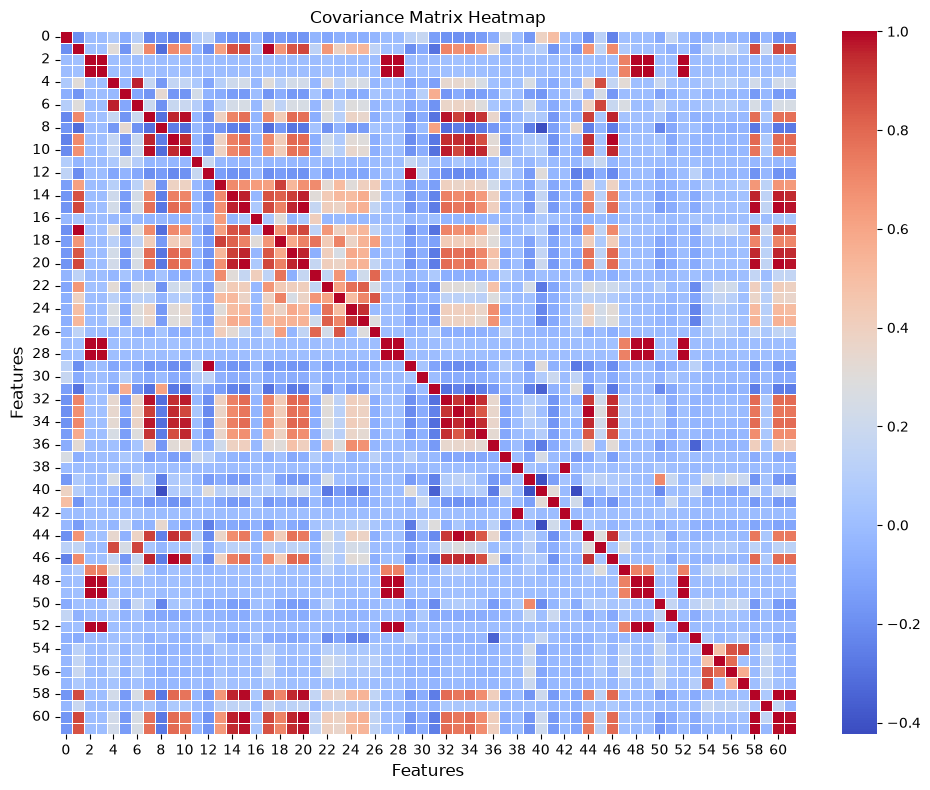

In [90]:
# Preprocessing sequence 
# Visualization only — GlassBoost training data is unchanged

# LOAD THE ORIGINAL DATASET
df_cov = pd.read_csv(
    "Wednesday-workingHours.pcap_ISCX.csv",
    low_memory=False
)

# REMOVE MISSING AND INFINITE VALUES
df_cov = df_cov.dropna()

df_cov = df_cov.loc[
    ~df_cov.isin([np.inf, -np.inf]).any(axis=1)
].copy()

print("Dataset shape after cleaning:", df_cov.shape)

# SELECT FEATURE COLUMNS
# Match alt.ipynb: exclude the final column
features_cov = df_cov.iloc[:, :-1].copy()

print("Initial feature count:", features_cov.shape[1])

# REMOVE ZERO-VARIANCE FEATURES
zero_variance_mask = features_cov.var() == 0

zero_variance_features = features_cov.columns[
    zero_variance_mask
].tolist()

features_cov = features_cov.drop(
    columns=zero_variance_features
)

print("Zero-variance features removed:", len(zero_variance_features))
print("Features remaining:", features_cov.shape[1])

#  IDENTIFY DUPLICATE-VALUED FEATURE PAIRS
duplicate_feature_pairs = []

for first_feature in features_cov.columns:
    for second_feature in features_cov.columns:
        if (
            first_feature != second_feature
            and features_cov[first_feature].equals(
                features_cov[second_feature]
            )
        ):
            duplicate_feature_pairs.append(
                (first_feature, second_feature)
            )

# Match the duplicate-pair handling used in alt.ipynb
unique_duplicate_pairs = {
    tuple(sorted(pair))
    for pair in duplicate_feature_pairs
}

duplicate_features_to_remove = [
    pair[1] for pair in unique_duplicate_pairs
]

features_cov = features_cov.drop(
    columns=duplicate_features_to_remove
)

print("Duplicate features removed:", len(duplicate_features_to_remove))
print("Final feature count:", features_cov.shape[1])

# STANDARDIZE FEATURES
cov_scaler = StandardScaler()

standardized_features = cov_scaler.fit_transform(
    features_cov
)

# CALCULATE THE COVARIANCE MATRIX
cov_matrix = np.cov(
    standardized_features,
    rowvar=False
)

print("Covariance matrix shape:", cov_matrix.shape)
print("Minimum covariance:", cov_matrix.min())
print("Maximum covariance:", cov_matrix.max())
print("Matrix symmetric:", np.allclose(cov_matrix, cov_matrix.T))

# PLOT THE COVARIANCE MATRIX
plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    cov_matrix,
    annot=False,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    cbar=True
)

plt.title("Covariance Matrix Heatmap", fontsize=12)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Features", fontsize=12)

# Display feature indices every 2 positions
number_of_features = cov_matrix.shape[0]
ticks = np.arange(0, number_of_features, 2)

ax.set_xticks(ticks + 0.5)
ax.set_yticks(ticks + 0.5)

ax.set_xticklabels(ticks, rotation=0)
ax.set_yticklabels(ticks, rotation=0)

plt.tight_layout()
plt.show() 


In [91]:
print("Matrix shape:", cov_matrix.shape)
print("Minimum:", cov_matrix.min())
print("Maximum:", cov_matrix.max())

print("Symmetric:", np.allclose(
    cov_matrix, cov_matrix.T, atol=1e-8
))

print("Diagonal values:")
print(np.round(np.diag(cov_matrix)[:10], 3))



Matrix shape: (62, 62)
Minimum: -0.42361660991131084
Maximum: 1.0000014463303388
Symmetric: True
Diagonal values:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [92]:

#  PREPARE FEATURES FOR SPLITTING
# Standardization will be performed AFTER splitting
# to prevent data leakage.

X_processed = X.copy()

print("Features ready for splitting:", X_processed.shape)


Features ready for splitting: (691406, 62)


In [93]:
# QUICK PREPROCESSING DIAGNOSTICS
# Raw feature covariances can be extremely large because the feature units differ.
# Use the standardized-feature matrix from Cell 6 for a meaningful covariance range.
print("\nStandardized-feature covariance range:")
print("Minimum:", round(float(np.min(cov_matrix)), 4))
print("Maximum:", round(float(np.max(cov_matrix)), 4))

print("\nFirst 15 feature names:")
print(X_processed.columns[:15].tolist())

print("\nDiagonal values of standardized-feature covariance matrix (first 10):")
print(np.round(np.diag(cov_matrix)[:10], 4))

print("\nFeatures:", X_processed.shape)
print("Labels:", y_binary.shape)

assert len(X_processed) == len(y_binary)
assert X_processed.index.equals(y_binary.index)

print("Feature-target alignment check passed!")



Standardized-feature covariance range:
Minimum: -0.4236
Maximum: 1.0

First 15 feature names:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s']

Diagonal values of standardized-feature covariance matrix (first 10):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Features: (691406, 62)
Labels: (691406,)
Feature-target alignment check passed!


In [94]:
#  FINAL CHECKS

print("\n FINAL PREPROCESSING SUMMARY")
print("Records:", len(X_processed))
print("Features:", X_processed.shape[1])
print("Missing values:", X_processed.isna().sum().sum())
print("Infinite values:", np.isinf(X_processed.to_numpy()).sum())
print("Constant features remaining:", (X_processed.nunique() <= 1).sum())
print("\nFinal class counts:")
print(y_binary.value_counts().sort_index())

# These variables are ready for the next paper section:
# X_scaled = preprocessed features
# y_binary = binary target labels


 FINAL PREPROCESSING SUMMARY
Records: 691406
Features: 62
Missing values: 0
Infinite values: 0
Constant features remaining: 0

Final class counts:
Label
0    439683
1    251723
Name: count, dtype: int64


In [95]:
# PREPARE DATA WITHOUT OVERLAPPING TEST DATA

from sklearn.model_selection import train_test_split

X_processed = X_processed.reset_index(drop=True)
y_binary = y_binary.reset_index(drop=True)

# First, create one untouched final test set
X_train, X_test, y_train, y_test = train_test_split(
    X_processed,
    y_binary,
    test_size=0.30,
    random_state=42,
    stratify=y_binary
)

# Use only the training portion to create training and validation sets
X_train_tree, X_val_tree, y_train_tree, y_val_tree = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# XGBoost uses the training portion and is evaluated on the same final test set
X_train_xgb = X_train.copy()
y_train_xgb = y_train.copy()

X_test_xgb = X_test.copy()
y_test_xgb = y_test.copy()

print("Training data:", X_train.shape)
print("Tree training data:", X_train_tree.shape)
print("Tree validation data:", X_val_tree.shape)
print("Final test data:", X_test.shape)

Training data: (483984, 62)
Tree training data: (387187, 62)
Tree validation data: (96797, 62)
Final test data: (207422, 62)


In [96]:
# PREPARE DATA FOR TREE-BASED MODELS
# XGBoost and Decision Trees do not require standardization.
# Keeping original feature values also makes rules easier to interpret.

X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

print("Using original feature values.")
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Tree training data:", X_train_tree.shape)
print("Tree validation data:", X_val_tree.shape)

Using original feature values.
Training data: (483984, 62)
Test data: (207422, 62)
Tree training data: (387187, 62)
Tree validation data: (96797, 62)


In [97]:
#  TRAIN AND EVALUATE BASELINE XGBOOST WITHOUT TEST-SET MONITORING
# First monitor loss on an inner train/validation split.
# Then refit the final baseline on all outer-training rows and evaluate once on X_test.
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Preserve original feature names for mapping
original_features = X_train.columns.tolist()
safe_features = [f"f{i}" for i in range(len(original_features))]

def make_safe_columns(frame):
    result = frame[original_features].copy()
    result.columns = safe_features
    return result

X_train_tree_safe = make_safe_columns(X_train_tree)
X_val_tree_safe = make_safe_columns(X_val_tree)
X_train_xgb_safe = make_safe_columns(X_train)
X_test_xgb_safe = make_safe_columns(X_test)

# Model for the training and validation loss plot
xgb_curve_model = XGBClassifier(
    n_estimators=50,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_curve_model.fit(
    X_train_tree_safe,
    y_train_tree,
    eval_set=[
        (X_train_tree_safe, y_train_tree),
        (X_val_tree_safe, y_val_tree)
    ],
    verbose=False
)

# Final baseline model: fit on the entire outer training set
# Do not pass the test set into eval_set.
xgb_model = XGBClassifier(
    n_estimators=50,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_xgb_safe, y_train)

xgb_test_predictions = xgb_model.predict(X_test_xgb_safe)

print("XGBoost Test Performance")
print("Accuracy:", round(
    accuracy_score(y_test, xgb_test_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, xgb_test_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, xgb_test_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, xgb_test_predictions, zero_division=0), 4
))

XGBoost Test Performance
Accuracy: 0.9969
Precision: 0.9937
Recall: 0.9979
F1-score: 0.9958


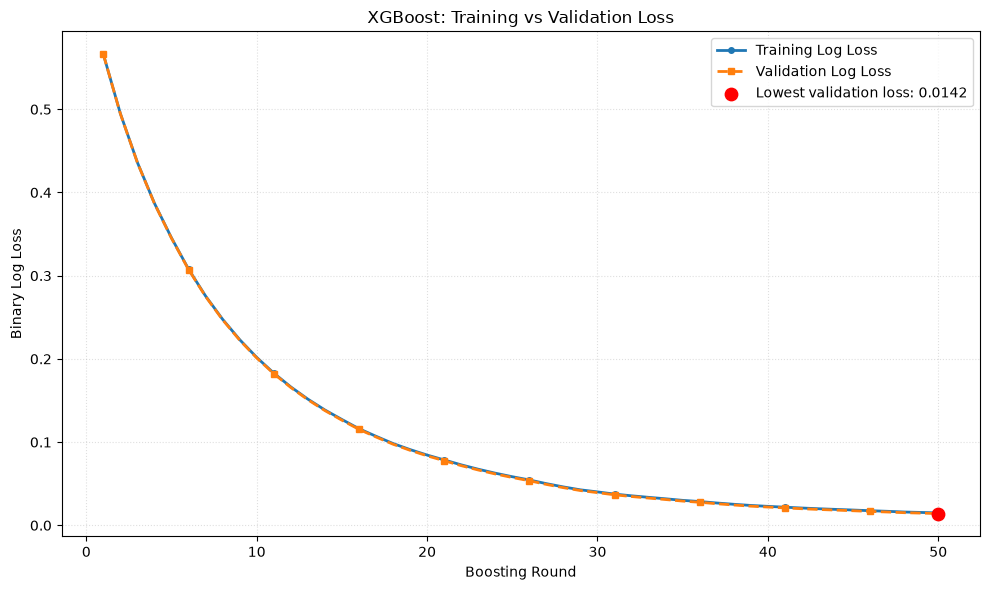

Lowest validation loss: 0.01416
Best boosting round: 50


In [98]:
#  XGBOOST TRAINING VS VALIDATION LOG LOSS
# Distinct styles/markers keep both curves visible when their values are close.

evals_result = xgb_curve_model.evals_result()

train_loss = evals_result["validation_0"]["logloss"]
val_loss = evals_result["validation_1"]["logloss"]

rounds = np.arange(1, len(train_loss) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    rounds,
    train_loss,
    color="tab:blue",
    linestyle="-",
    linewidth=2,
    marker="o",
    markersize=4,
    markevery=5,
    label="Training Log Loss"
)

plt.plot(
    rounds,
    val_loss,
    color="tab:orange",
    linestyle="--",
    linewidth=2,
    marker="s",
    markersize=4,
    markevery=5,
    label="Validation Log Loss"
)

best_round = int(np.argmin(val_loss))
best_loss = val_loss[best_round]

plt.scatter(
    rounds[best_round],
    best_loss,
    color="red",
    s=80,
    zorder=5,
    label=f"Lowest validation loss: {best_loss:.4f}"
)

plt.xlabel("Boosting Round")
plt.ylabel("Binary Log Loss")
plt.title("XGBoost: Training vs Validation Loss")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()

print("Lowest validation loss:", round(best_loss, 5))
print("Best boosting round:", best_round + 1)

In [99]:

# EXTRACT RAW GAIN, COVER, AND WEIGHT SCORES

booster = xgb_model.get_booster()

gain_scores = booster.get_score(importance_type="gain")
cover_scores = booster.get_score(importance_type="cover")
weight_scores = booster.get_score(importance_type="weight")

importance_rows = []

for i, feature in enumerate(original_features):
    safe_name = f"f{i}"

    importance_rows.append({
        "Feature": feature,
        "Gain": gain_scores.get(safe_name, 0.0),
        "Cover": cover_scores.get(safe_name, 0.0),
        "Weight": weight_scores.get(safe_name, 0.0)
    })

importance_df = pd.DataFrame(importance_rows)

# Rank using raw gain values
importance_df = importance_df.sort_values(
    by="Gain",
    ascending=False
).reset_index(drop=True)

print("Feature importance scores (raw values):")
print(importance_df.to_string(index=False))

print("\nTop 10 features by gain:")
print(importance_df.head(10).to_string(index=False))

# Save the original importance scores
importance_df.to_csv(
    "glassboost_feature_importance.csv",
    index=False
)


Feature importance scores (raw values):
                    Feature         Gain        Cover  Weight
         Packet Length Mean 37572.886719 42306.109375    12.0
              Bwd Packets/s 31556.386719 43988.929688    20.0
      Bwd Packet Length Std 23500.119141 27998.023438    48.0
          Min Packet Length  6996.092773 26029.474609    16.0
           Destination Port  4775.338379  9582.369141   121.0
                 Active Std  3300.123535 57394.750000     5.0
             URG Flag Count  2905.561523  7990.148438     1.0
             FIN Flag Count  2430.249756 17040.083984    24.0
    Init_Win_bytes_backward  2117.362305  8163.956055    67.0
        Average Packet Size  2082.334717  1994.852539     1.0
             Flow Packets/s  1980.958740 13035.287109     5.0
                Bwd IAT Std  1840.331787 49291.406250     5.0
              Flow IAT Mean  1801.965210  7544.807617     5.0
     Bwd Packet Length Mean  1356.136230  6187.536621    12.0
                  Idle Mean  1

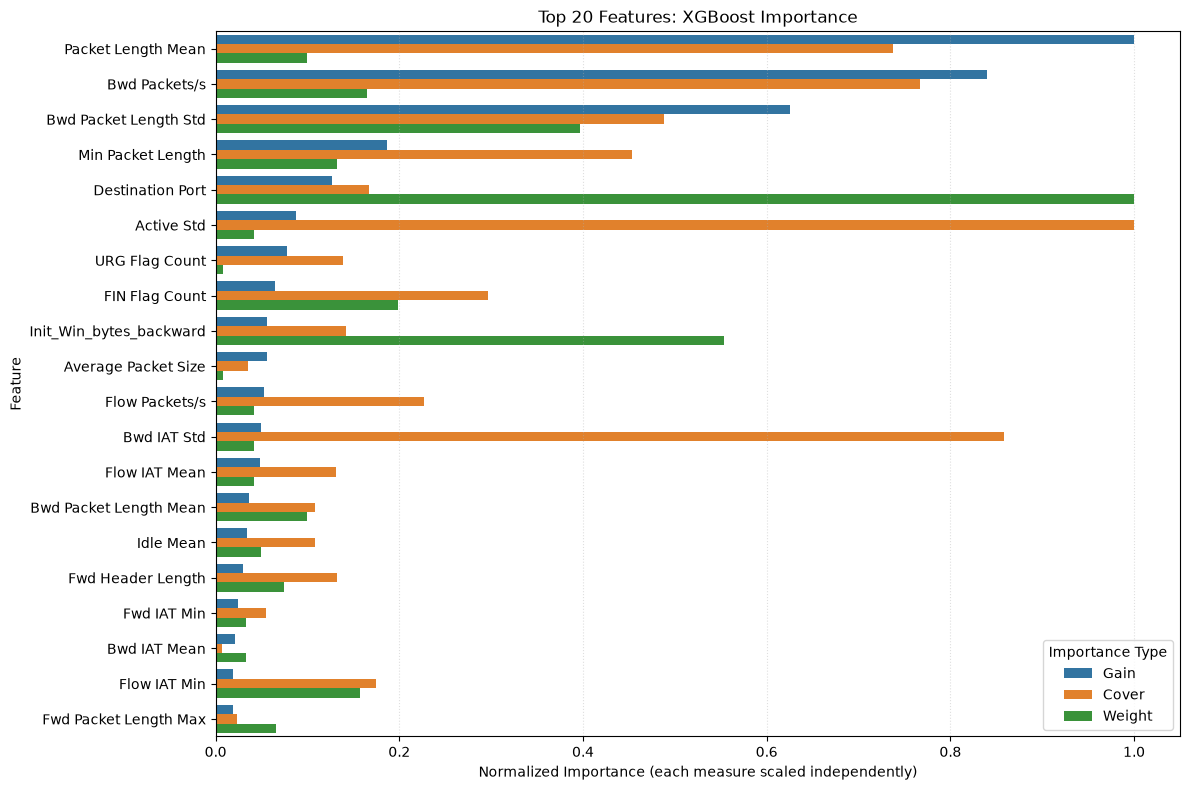

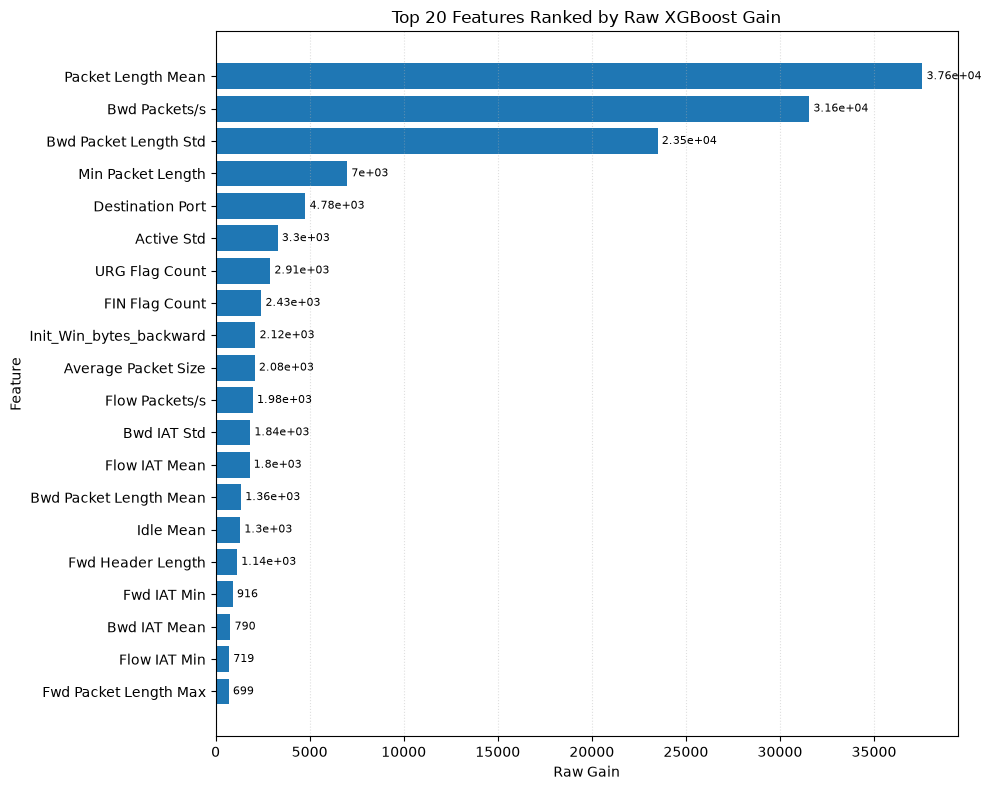

In [100]:
top_n = min(20, len(importance_df))
top_features = importance_df.head(top_n).copy()

# Normalize a plotting copy so the three importance types
# can be compared on a common 0–1 scale.
plot_df = top_features.copy()

for metric in ["Gain", "Cover", "Weight"]:
    maximum = importance_df[metric].max()

    if maximum > 0:
        plot_df[metric] = plot_df[metric] / maximum
    else:
        plot_df[metric] = 0.0

plot_long = plot_df.melt(
    id_vars="Feature",
    value_vars=["Gain", "Cover", "Weight"],
    var_name="Importance Type",
    value_name="Normalized Score"
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=plot_long,
    y="Feature",
    x="Normalized Score",
    hue="Importance Type"
)

plt.title("Top 20 Features: XGBoost Importance")
plt.xlabel("Normalized Importance (each measure scaled independently)")
plt.ylabel("Feature")
plt.xlim(0, 1.05)
plt.legend(title="Importance Type")
plt.grid(axis="x", linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()


# Separate raw Gain plot
gain_plot = (
    importance_df.head(top_n)
    .sort_values("Gain", ascending=True)
)

plt.figure(figsize=(10, 8))

bars = plt.barh(
    gain_plot["Feature"],
    gain_plot["Gain"]
)

plt.bar_label(bars, fmt="%.3g", padding=3, fontsize=8)

plt.title("Top 20 Features Ranked by Raw XGBoost Gain")
plt.xlabel("Raw Gain")
plt.ylabel("Feature")
plt.grid(axis="x", linestyle=":", alpha=0.4)
plt.tight_layout()
plt.show()

In [101]:
# Use only the outer training data
X_glass_pool = X_train.reset_index(drop=True)
y_glass_pool = y_train.reset_index(drop=True)

# Sample at most 40,000 records
sample_size = min(40000, len(X_glass_pool))

X_glass_sample, _, y_glass_sample, _ = train_test_split(
    X_glass_pool,
    y_glass_pool,
    train_size=sample_size,
    random_state=42,
    stratify=y_glass_pool
)

# Split into GlassBoost training and validation sets
X_glass_train, X_glass_val, y_glass_train, y_glass_val = (
    train_test_split(
        X_glass_sample,
        y_glass_sample,
        test_size=0.20,
        random_state=42,
        stratify=y_glass_sample
    )
)

# Learn feature ranking from GlassBoost training data ONLY
ranking_features = X_glass_train.columns.tolist()
ranking_safe_features = [
    f"f{i}" for i in range(len(ranking_features))
]

X_glass_train_safe = X_glass_train.copy()
X_glass_train_safe.columns = ranking_safe_features

ranking_model = XGBClassifier(
    n_estimators=50,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

ranking_model.fit(
    X_glass_train_safe,
    y_glass_train
)

# Extract Gain scores
gain_scores = ranking_model.get_booster().get_score(
    importance_type="gain"
)

gain_ranking = pd.DataFrame({
    "Feature": ranking_features,
    "Gain": [
        gain_scores.get(f"f{i}", 0.0)
        for i in range(len(ranking_features))
    ]
})

gain_ranking = gain_ranking.sort_values(
    "Gain",
    ascending=False
).reset_index(drop=True)

ranked_features = gain_ranking["Feature"].tolist()

print("Top 10 GlassBoost training features:")
print(gain_ranking.head(10).to_string(index=False))

# Experiment with different tree depths and feature counts
depth_values = [3, 4, 5]
max_features = min(40, len(ranked_features))

results = []

for depth in depth_values:
    for n_features in range(1, max_features + 1):

        selected_features = ranked_features[:n_features]

        tree_model = DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            random_state=42
        )

        tree_model.fit(
            X_glass_train[selected_features],
            y_glass_train
        )

        predictions = tree_model.predict(
            X_glass_val[selected_features]
        )

        results.append({
            "Depth": depth,
            "Number of Features": n_features,
            "Accuracy": accuracy_score(
                y_glass_val, predictions
            ),
            "Precision": precision_score(
                y_glass_val, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_glass_val, predictions,
                zero_division=0
            ),
            "F1-score": f1_score(
                y_glass_val, predictions,
                zero_division=0
            )
        })

    print(f"Completed experiments for depth {depth}")

results_df = pd.DataFrame(results)

print("\nTop 10 configurations by validation F1-score:")
print(
    results_df.sort_values(
        ["F1-score", "Recall", "Number of Features", "Depth"],
        ascending=[False, False, True, True]
    ).head(10).round(4).to_string(index=False)
)

results_df.to_csv(
    "glassboost_experiment_results.csv",
    index=False
)

print("\nResults saved to glassboost_experiment_results.csv")

Top 10 GlassBoost training features:
                Feature        Gain
     Packet Length Mean 3340.211914
          Bwd Packets/s 2966.862305
  Bwd Packet Length Std 1496.051147
      Min Packet Length  392.679169
       Destination Port  316.624908
Init_Win_bytes_backward  221.948044
         FIN Flag Count  212.077560
             Active Std  182.916870
 Bwd Packet Length Mean  149.340729
            Bwd IAT Std  136.304901
Completed experiments for depth 3
Completed experiments for depth 4
Completed experiments for depth 5

Top 10 configurations by validation F1-score:
 Depth  Number of Features  Accuracy  Precision  Recall  F1-score
     5                   5    0.9902     0.9866  0.9866    0.9866
     5                   6    0.9886     0.9777  0.9914    0.9845
     5                   7    0.9886     0.9777  0.9914    0.9845
     5                  12    0.9882     0.9842  0.9835    0.9839
     5                  13    0.9882     0.9842  0.9835    0.9839
     5                

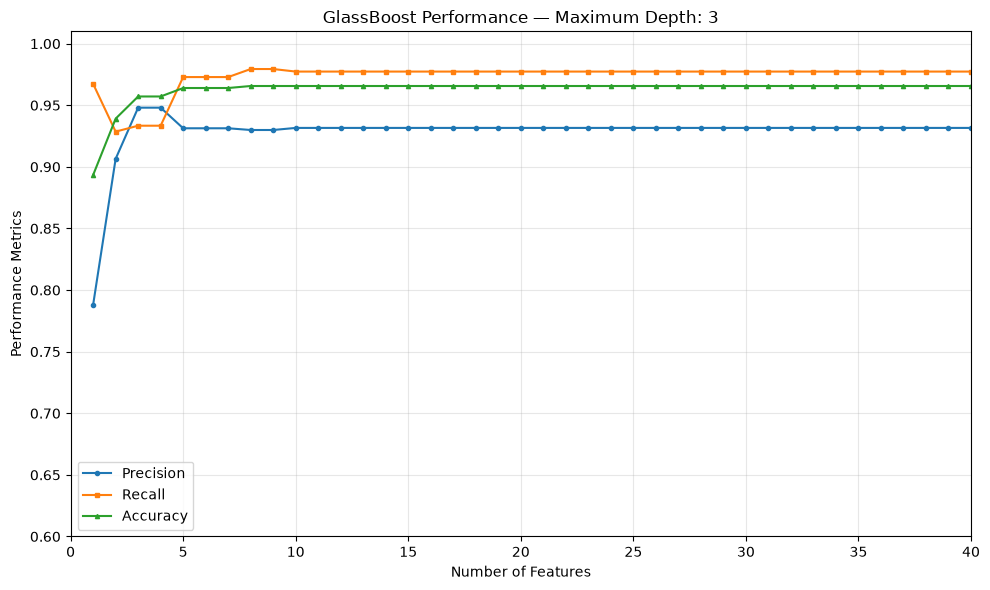

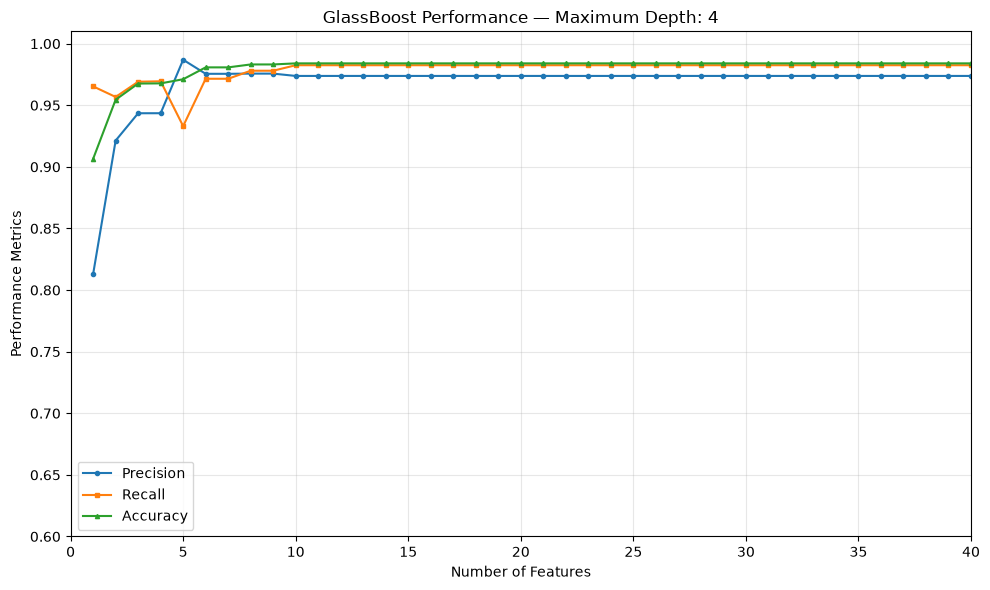

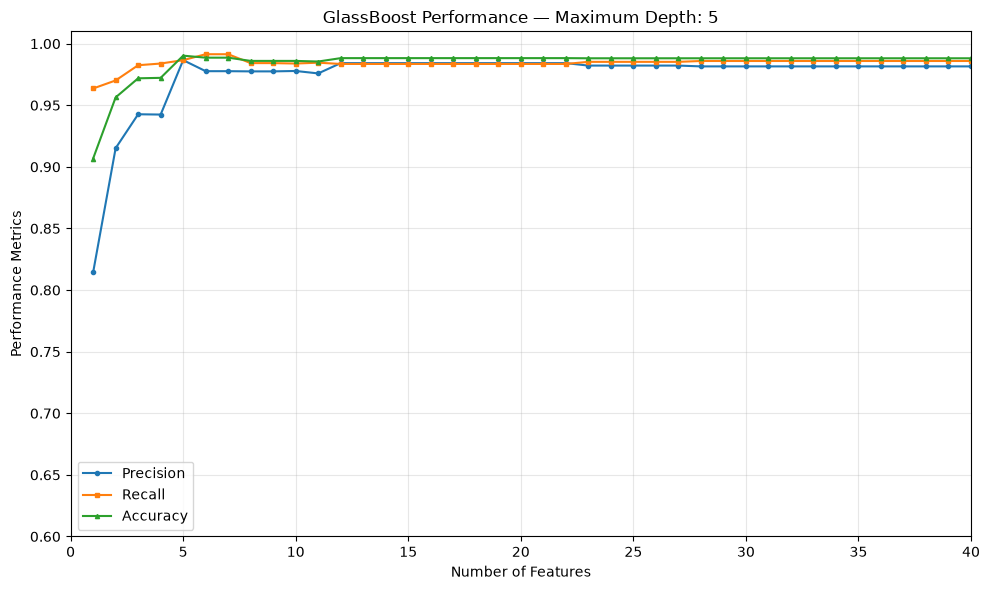

In [102]:
import matplotlib.pyplot as plt

# One separate figure for each tree depth: 3, 4, and 5
for depth in [3, 4, 5]:

    plot_df = results_df[
        results_df["Depth"] == depth
    ].sort_values("Number of Features")

    if plot_df.empty:
        print(f"No results found for depth {depth}")
        continue

    plt.figure(figsize=(10, 6))

    plt.plot(
        plot_df["Number of Features"],
        plot_df["Precision"],
        marker="o",
        markersize=3,
        label="Precision"
    )

    plt.plot(
        plot_df["Number of Features"],
        plot_df["Recall"],
        marker="s",
        markersize=3,
        label="Recall"
    )

    plt.plot(
        plot_df["Number of Features"],
        plot_df["Accuracy"],
        marker="^",
        markersize=3,
        label="Accuracy"
    )

    plt.title(
        f"GlassBoost Performance — Maximum Depth: {depth}"
    )
    plt.xlabel("Number of Features")
    plt.ylabel("Performance Metrics")
    plt.xlim(1, 40)
    plt.ylim(0.60, 1.01)
    plt.xticks(range(0, 41, 5))
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [103]:

#  SELECT ON VALIDATION, THEN EVALUATE ON FINAL TEST SET

# Choose a configuration using validation results only.
# Prefer higher accuracy and recall, then fewer features and lower depth.

# Select the best configuration using validation results only.
# Prioritize F1-score and recall, then model simplicity.

best_row = results_df.sort_values(
    by=[
        "F1-score",
        "Recall",
        "Number of Features",
        "Depth"
    ],
    ascending=[False, False, True, True]
).iloc[0]


best_depth = int(best_row["Depth"])
best_d = int(best_row["Number of Features"])
best_features = ranked_features[:best_d]

print("Selected maximum depth:", best_depth)
print("Selected number of features:", best_d)

print("\nSelected features:")
for i, feature in enumerate(best_features, start=1):
    print(f"{i}. {feature}")

# Retrain on the full training partition
best_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=best_depth,
    random_state=42
)

best_model.fit(
    X_train[best_features],
    y_train
)

# Evaluate once on the untouched final test set
best_predictions = best_model.predict(
    X_test[best_features]
)

print("\nFINAL GLASSBOOST TEST PERFORMANCE")
print("Accuracy:", round(
    accuracy_score(y_test, best_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, best_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, best_predictions, zero_division=0), 4
))
print("F1-score:", round(
    f1_score(y_test, best_predictions, zero_division=0), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, best_predictions))

print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    zero_division=0
))


Selected maximum depth: 5
Selected number of features: 5

Selected features:
1. Packet Length Mean
2. Bwd Packets/s
3. Bwd Packet Length Std
4. Min Packet Length
5. Destination Port

FINAL GLASSBOOST TEST PERFORMANCE
Accuracy: 0.9871
Precision: 0.9913
Recall: 0.973
F1-score: 0.9821

Confusion matrix:
[[131261    644]
 [  2040  73477]]

Classification report:
              precision    recall  f1-score   support

      BENIGN       0.98      1.00      0.99    131905
      ATTACK       0.99      0.97      0.98     75517

    accuracy                           0.99    207422
   macro avg       0.99      0.98      0.99    207422
weighted avg       0.99      0.99      0.99    207422



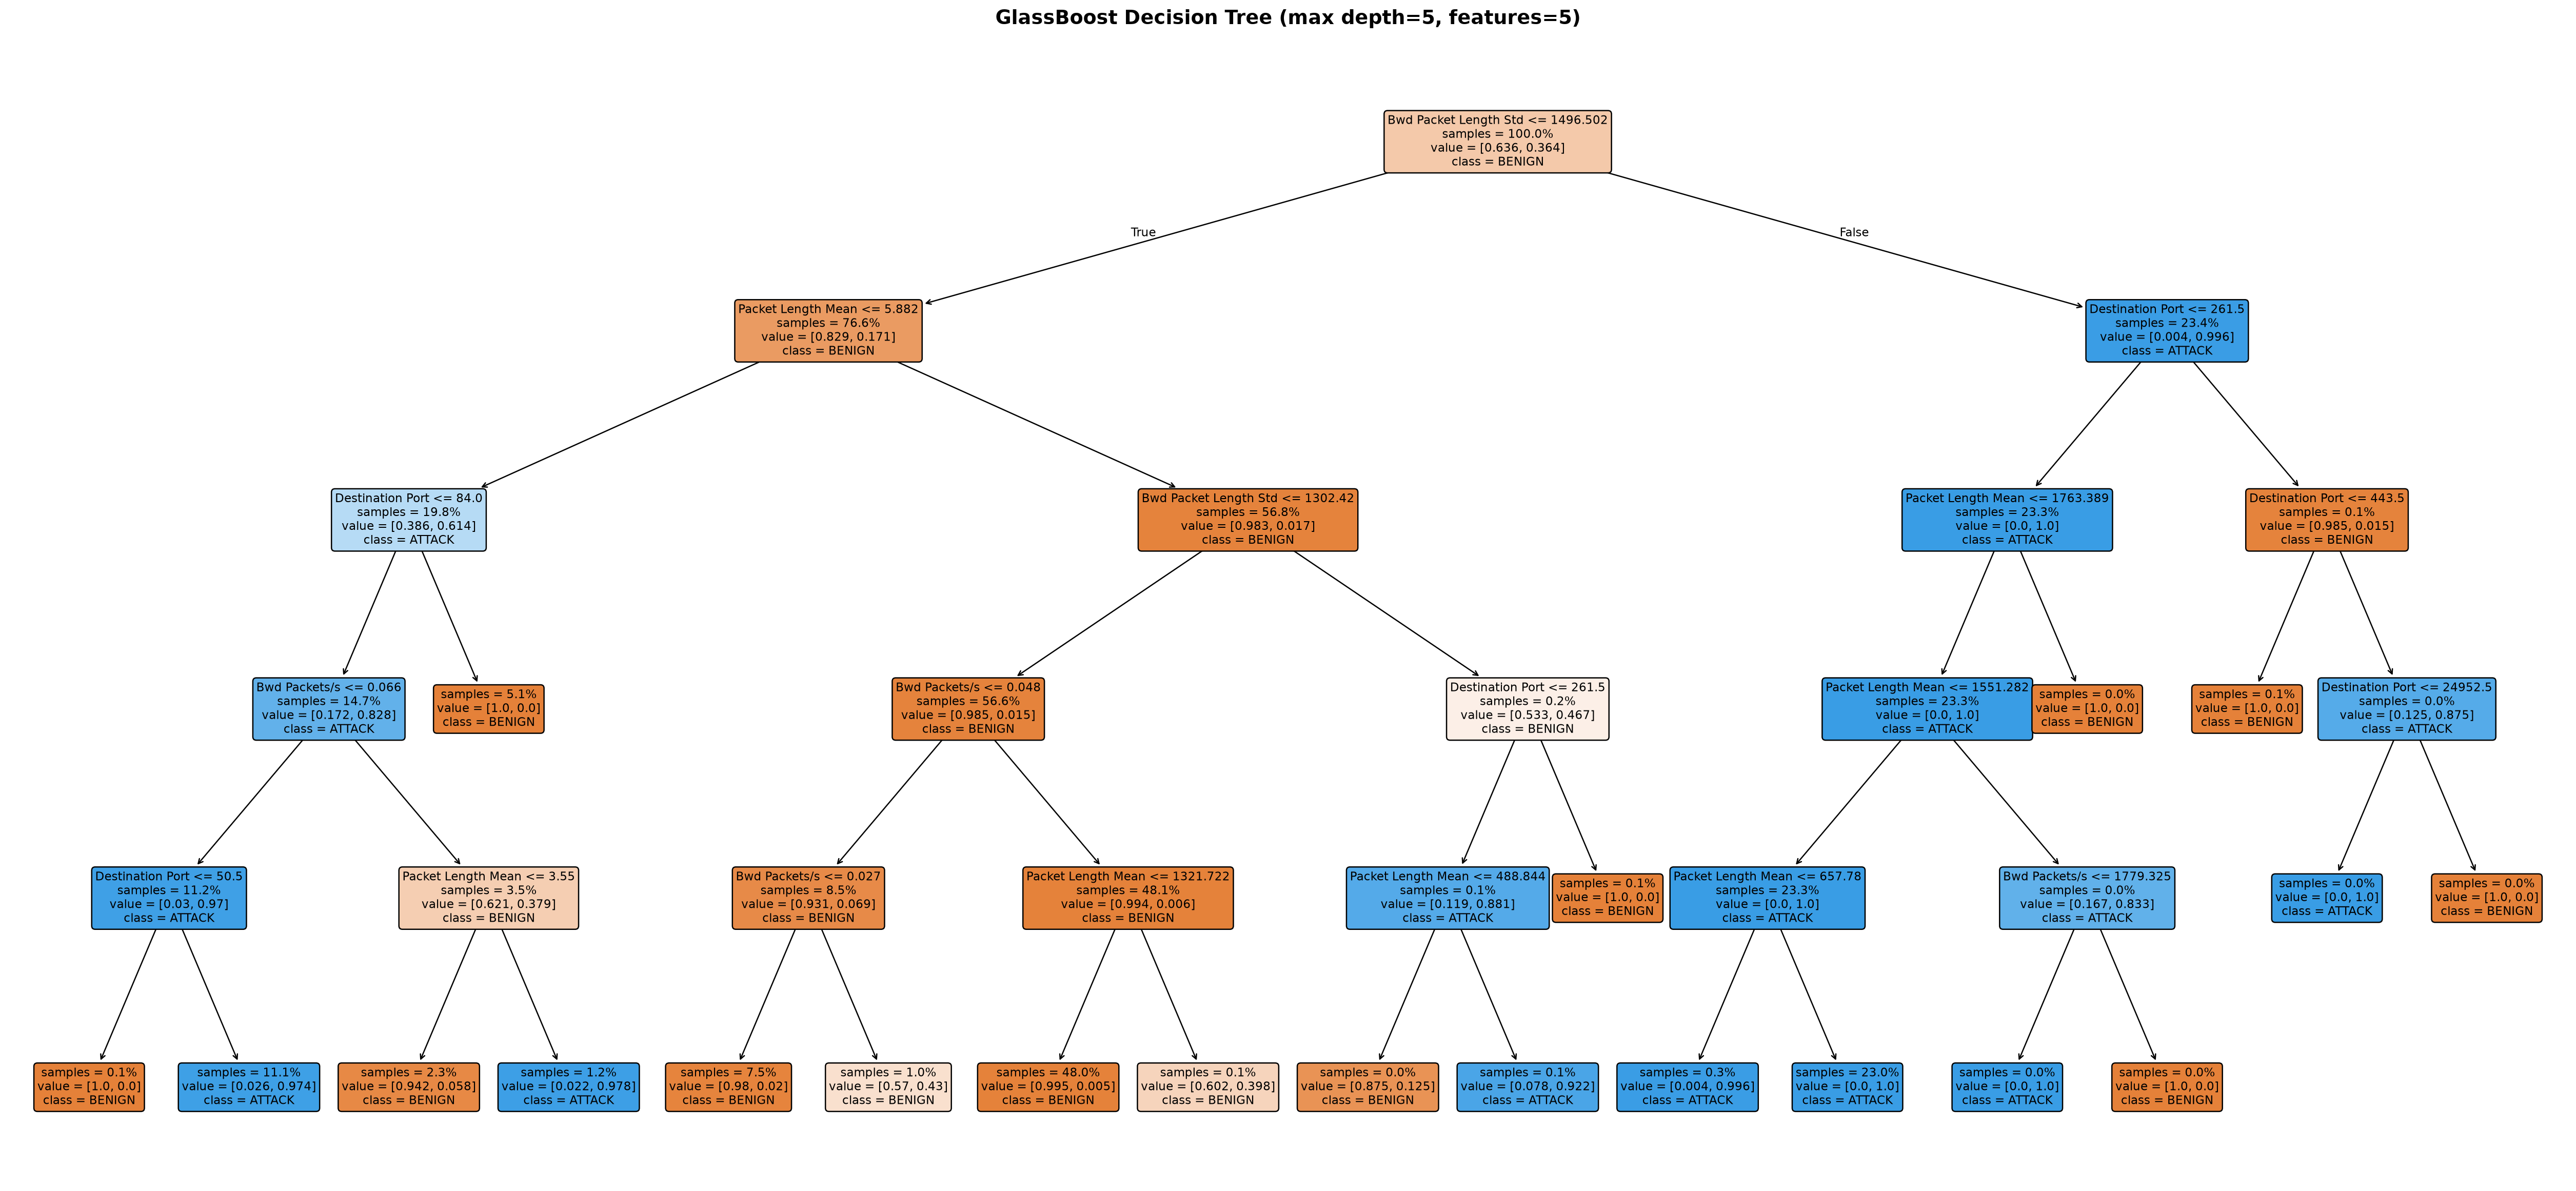

In [104]:
# PLOT THE SELECTED GLASSBOOST DECISION TREE
# High DPI and slightly larger text improve readability when zooming into the figure.

fig, ax = plt.subplots(figsize=(28, 13), dpi=180)
plot_tree(
    best_model,
    feature_names=best_features,
    class_names=["BENIGN", "ATTACK"],
    filled=True,
    rounded=True,
    proportion=True,
    impurity=False,
    precision=3,
    fontsize=9,
    ax=ax
)
ax.set_title(
    f"GlassBoost Decision Tree (max depth={best_depth}, features={best_d})",
    fontsize=15,
    weight="bold",
    pad=18
)
fig.tight_layout()
fig.savefig("glassboost_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()


In [105]:
#  EXTRACT DECISION RULES

rules = export_text(
    best_model,
    feature_names=best_features,
    decimals=4
)

print("GLASSBOOST IF-THEN RULES")

print(rules)

with open(
    "glassboost_rules.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(rules)

print("Rules saved to glassboost_rules.txt")

GLASSBOOST IF-THEN RULES
|--- Bwd Packet Length Std <= 1496.5020
|   |--- Packet Length Mean <= 5.8819
|   |   |--- Destination Port <= 84.0000
|   |   |   |--- Bwd Packets/s <= 0.0664
|   |   |   |   |--- Destination Port <= 50.5000
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Destination Port >  50.5000
|   |   |   |   |   |--- class: 1
|   |   |   |--- Bwd Packets/s >  0.0664
|   |   |   |   |--- Packet Length Mean <= 3.5500
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Packet Length Mean >  3.5500
|   |   |   |   |   |--- class: 1
|   |   |--- Destination Port >  84.0000
|   |   |   |--- class: 0
|   |--- Packet Length Mean >  5.8819
|   |   |--- Bwd Packet Length Std <= 1302.4202
|   |   |   |--- Bwd Packets/s <= 0.0480
|   |   |   |   |--- Bwd Packets/s <= 0.0268
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Bwd Packets/s >  0.0268
|   |   |   |   |   |--- class: 0
|   |   |   |--- Bwd Packets/s >  0.0480
|   |   |   |   |--- Packet Length Mean <= 1321

Top 10 SHAP features:
                Feature  SHAP Importance
       Destination Port         1.347721
  Bwd Packet Length Std         1.201296
          Bwd Packets/s         0.794346
Init_Win_bytes_backward         0.582758
      Min Packet Length         0.499740
     Packet Length Mean         0.411459
 Bwd Packet Length Mean         0.299384
              Idle Mean         0.165035
           Flow IAT Min         0.142526
         FIN Flag Count         0.125077


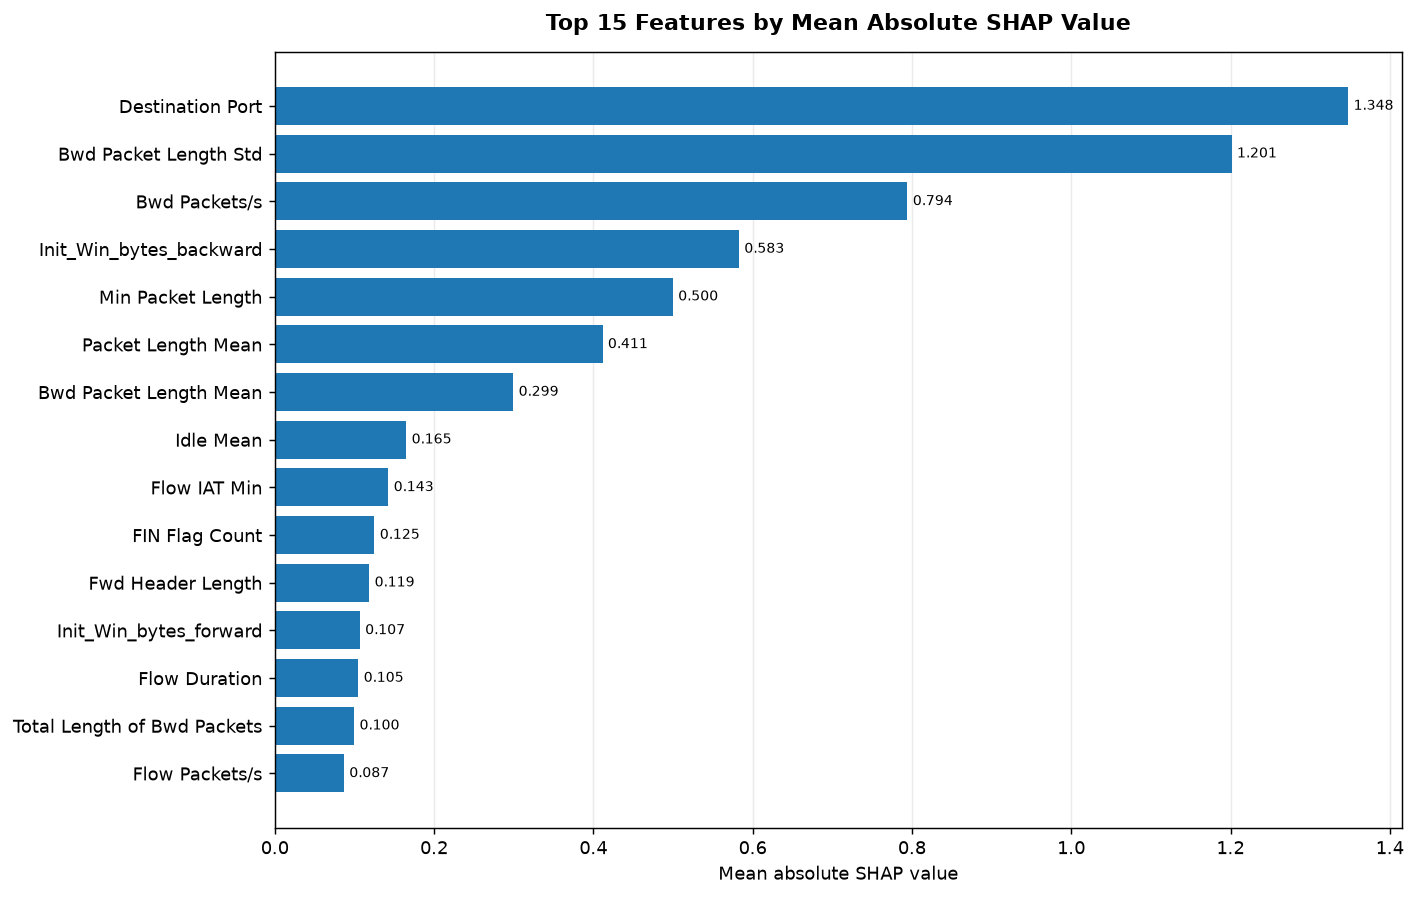


SHAP decision tree — final test performance
Precision: 0.9895
Recall: 0.9973
Accuracy: 0.9952
F1-score: 0.9934


In [106]:
# OPTIONAL SHAP FEATURE IMPORTANCE AND TREE COMPARISON

try:
    import shap

    # Use a subset of training data to reduce computation time
    shap_sample_size = min(2000, len(X_train_xgb_safe))

    X_shap = X_train_xgb_safe.sample(
        n=shap_sample_size,
        random_state=42
    )

    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_shap)

    if isinstance(shap_values, list):
        shap_array = np.asarray(shap_values[-1])
    else:
        shap_array = np.asarray(shap_values)

    if shap_array.ndim == 3:
        shap_array = shap_array[:, :, -1]

    mean_abs_shap = np.mean(np.abs(shap_array), axis=0)

    shap_importance = pd.DataFrame({
        "Feature": original_features,
        "SHAP Importance": mean_abs_shap
    }).sort_values(
        "SHAP Importance",
        ascending=False
    ).reset_index(drop=True)

    print("Top 10 SHAP features:")
    print(shap_importance.head(10).to_string(index=False))

    top_shap = shap_importance.head(15).sort_values("SHAP Importance")

    fig, ax = plt.subplots(figsize=(11, 7), dpi=130)
    bars = ax.barh(top_shap["Feature"], top_shap["SHAP Importance"])
    ax.set_title("Top 15 Features by Mean Absolute SHAP Value", weight="bold", pad=12)
    ax.set_xlabel("Mean absolute SHAP value")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
    fig.tight_layout()
    plt.show()

    # Use the same number of features and tree depth as GlassBoost
    shap_features = shap_importance["Feature"].head(best_d).tolist()

    shap_tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=best_depth,
        random_state=42
    )

    shap_tree.fit(
        X_train[shap_features],
        y_train
    )

    shap_predictions = shap_tree.predict(
        X_test[shap_features]
    )

    print("\nSHAP decision tree — final test performance")
    print("Precision:", round(
        precision_score(y_test, shap_predictions, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_test, shap_predictions, zero_division=0), 4
    ))
    print("Accuracy:", round(
        accuracy_score(y_test, shap_predictions), 4
    ))
    print("F1-score:", round(
        f1_score(y_test, shap_predictions, zero_division=0), 4
    ))

except ImportError:
    print("SHAP is not installed. Skipping the optional SHAP comparison.")
    print("Install it using: %pip install shap")

FINAL MODEL COMPARISON
             Model  Precision  Recall  Accuracy  F1-score
           XGBoost     0.9937  0.9979    0.9969    0.9958
        GlassBoost     0.9913  0.9730    0.9871    0.9821
SHAP Decision Tree     0.9895  0.9973    0.9952    0.9934


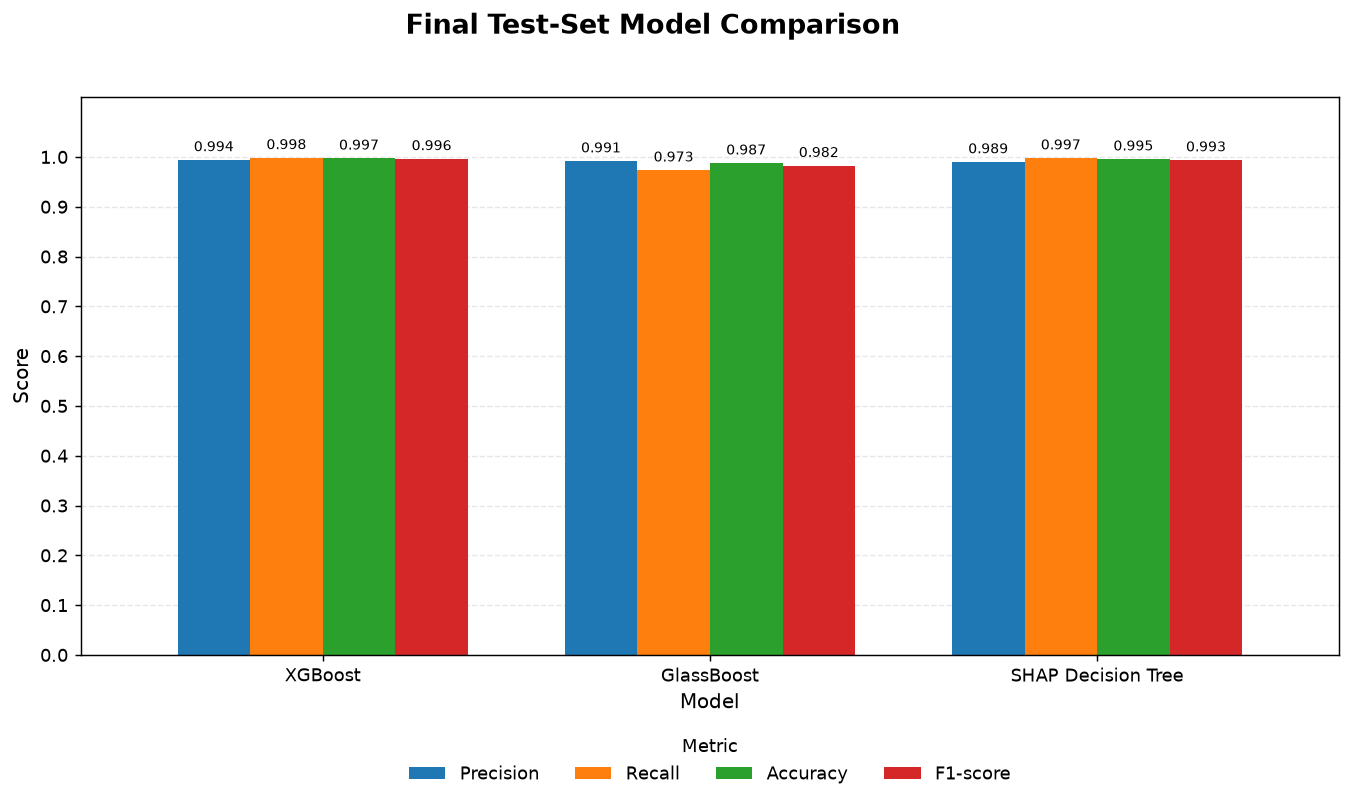

In [107]:
# MODEL COMPARISON
# All models are evaluated on the SAME final test set.

comparison_rows = []

# XGBoost
comparison_rows.append({
    "Model": "XGBoost",
    "Precision": precision_score(
        y_test_xgb, xgb_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_xgb, xgb_test_predictions, zero_division=0
    ),
    "Accuracy": accuracy_score(
        y_test_xgb, xgb_test_predictions
    ),
    "F1-score": f1_score(
        y_test_xgb, xgb_test_predictions, zero_division=0
    )
})

# GlassBoost
comparison_rows.append({
    "Model": "GlassBoost",
    "Precision": precision_score(
        y_test, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, best_predictions, zero_division=0
    ),
    "Accuracy": accuracy_score(
        y_test, best_predictions
    ),
    "F1-score": f1_score(
        y_test, best_predictions, zero_division=0
    )
})

# Add SHAP only if its model was successfully created
if "shap_predictions" in globals():
    comparison_rows.append({
        "Model": "SHAP Decision Tree",
        "Precision": precision_score(
            y_test, shap_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, shap_predictions, zero_division=0
        ),
        "Accuracy": accuracy_score(
            y_test, shap_predictions
        ),
        "F1-score": f1_score(
            y_test, shap_predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

print("FINAL MODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))

comparison_df.to_csv(
    "glassboost_model_comparison.csv",
    index=False
)


# COMPARISON FIGURE — CLEAR AND READABLE

plot_metrics = ["Precision", "Recall", "Accuracy", "F1-score"]
plot_df = comparison_df.set_index("Model")[plot_metrics]

fig, ax = plt.subplots(figsize=(11, 6.5), dpi=130)

plot_df.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    rot=0
)

# Title with enough space above the plot
fig.suptitle(
    "Final Test-Set Model Comparison",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

ax.set_xlabel("Model", fontsize=11)
ax.set_ylabel("Score", fontsize=11)
ax.set_ylim(0, 1.12)
ax.set_yticks(np.arange(0, 1.01, 0.1))

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Show values above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        fontsize=8,
        padding=3
    )

# Legend at the bottom — no overlap with title
ax.legend(
    title="Metric",
    ncol=4,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    frameon=False
)

# Reserve space for title and bottom legend
fig.subplots_adjust(
    top=0.88,
    bottom=0.22,
    left=0.10,
    right=0.98
)

plt.show()


In [108]:
#  SAVE EVERYTHING NEEDED FOR REUSE

import joblib

joblib.dump(
    {
        "model": best_model,
        "features": best_features,
        "depth": best_depth,
        "number_of_features": best_d,
        "label_mapping": {
            0: "BENIGN",
            1: "ATTACK"
        }
    },
    "glassboost_model.pkl"
)

comparison_df.to_csv(
    "glassboost_model_comparison.csv",
    index=False
)

print("Saved:")
print("1. glassboost_model.pkl")
print("2. glassboost_feature_importance.csv")
print("3. glassboost_experiment_results.csv")
print("4. glassboost_model_comparison.csv")
print("5. glassboost_rules.txt")

Saved:
1. glassboost_model.pkl
2. glassboost_feature_importance.csv
3. glassboost_experiment_results.csv
4. glassboost_model_comparison.csv
5. glassboost_rules.txt
